# senseBox:bike — temperature by trip and time

**Source identity:** this notebook uses the raw `osem_bike_data` collection from the [ATRAI API](https://api.atrai.bike/collections), documented on the [GreenCity bike-data page](https://hackathon.greencity.hn/resources/bike-data). It contains bike-mounted measurements from **all campaigns/cities**; this notebook keeps only records whose `groupTags` include the exact `heilbronn` tag.

This is not the same source as `data/alles.csv` just because that file's `recording` field contains `senseBox_bike`. Keep the CSV Mobile Datalogger analysis separate until its provenance is confirmed.

The API has more than a million raw features and documents `limit`/`offset` pagination. Date filtering is done locally after each page is downloaded, so the first run scans the collection. Matching rows are cached locally for the selected date. Change the date/time below to explore another period.


## Time and comparison caveats

The API's `createdAt` field is used as the measurement timestamp (`created_at` is the ingestion timestamp). Sample timestamps have no UTC offset or timezone suffix, so this notebook preserves their recorded clock values and **does not assume they are UTC or local time**. The common comparison window defaults to September 2, 2026, 10:00–14:00; confirm the API timestamp timezone before interpreting it as the same CEST window used by the CSV notebook.

A bike is moving, so its points represent a route and may repeatedly sample the same street. They are not equivalent to a fixed weather station. Temperature values also depend on sensor calibration, shade/sun, height, and route timing.


In [3]:
import gzip
import json
import time
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

TARGET_DATE = "2026-09-02"
START_TIME = "10:00"
END_TIME = "14:00"  # exclusive; timestamps are kept as recorded, timezone unverified
PAGE_SIZE = 10_000
REFRESH_CACHE = False
COLLECTION = "osem_bike_data"
API_URL = f"https://api.atrai.bike/collections/{COLLECTION}/items"

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CACHE_DIR = PROJECT_ROOT / "data" / "processed"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH = CACHE_DIR / f"{COLLECTION}_heilbronn_{TARGET_DATE}.csv"
print(f"Collection: {COLLECTION}; cache: {CACHE_PATH}")


Collection: osem_bike_data; cache: c:\Users\marce\Documents\GitHub\Tree-Mendous\data\processed\osem_bike_data_heilbronn_2026-09-02.csv


In [4]:
def parse_group_tags(value):
    if isinstance(value, str):
        try:
            value = json.loads(value)
        except json.JSONDecodeError:
            return []
    return value if isinstance(value, list) else []


def get_json_page(offset):
    request_url = f"{API_URL}?f=json&limit={PAGE_SIZE}&offset={offset}"
    request = Request(request_url, headers={"Accept-Encoding": "gzip"})
    with urlopen(request, timeout=90) as response:
        body = response.read()
        if response.headers.get("Content-Encoding") == "gzip":
            body = gzip.decompress(body)
    return json.loads(body)


def fetch_heilbronn_day():
    if CACHE_PATH.exists() and not REFRESH_CACHE:
        print("Using cached matching measurements. Set REFRESH_CACHE=True to rescan the API.")
        return pd.read_csv(CACHE_PATH)

    selected = []
    offset = 0
    total = None
    while total is None or offset < total:
        page = get_json_page(offset)
        total = page["numberMatched"]
        features = page.get("features", [])
        for feature in features:
            properties = feature.get("properties", {})
            timestamp = properties.get("createdAt")
            tags = parse_group_tags(properties.get("groupTags"))
            if not isinstance(timestamp, str) or timestamp[:10] != TARGET_DATE:
                continue
            if "heilbronn" not in [str(tag).lower() for tag in tags]:
                continue
            row = dict(properties)
            coordinates = feature.get("geometry", {}).get("coordinates") or []
            if len(coordinates) >= 2:
                row["longitude"] = coordinates[0]
                row["latitude"] = coordinates[1]
            selected.append(row)

        returned = page.get("numberReturned", len(features))
        if returned == 0:
            break
        offset += returned
        if offset % (PAGE_SIZE * 10) == 0 or offset >= total:
            print(f"Scanned {min(offset, total):,} / {total:,} features; matched {len(selected):,} Heilbronn rows for {TARGET_DATE}.")
        time.sleep(0.1)

    if not selected:
        raise ValueError(f"No Heilbronn bike measurements found for {TARGET_DATE}.")
    result = pd.DataFrame(selected)
    result.to_csv(CACHE_PATH, index=False)
    print(f"Cached {len(result):,} matching measurements at {CACHE_PATH}")
    return result


bike = fetch_heilbronn_day()
required = {"createdAt", "Temperature", "longitude", "latitude", "boxName"}
missing = required.difference(bike.columns)
if missing:
    raise ValueError(f"API response is missing expected fields: {sorted(missing)}")
bike["measurement_time"] = pd.to_datetime(bike["createdAt"], errors="coerce")
bike["Temperature"] = pd.to_numeric(bike["Temperature"], errors="coerce")
bike["longitude"] = pd.to_numeric(bike["longitude"], errors="coerce")
bike["latitude"] = pd.to_numeric(bike["latitude"], errors="coerce")
bike = bike.dropna(subset=["measurement_time", "Temperature", "longitude", "latitude"]).copy()
print(f"Usable rows: {len(bike):,}; bike boxes: {bike['boxName'].nunique()}")
display(bike[["createdAt", "boxName", "Temperature", "Rel. Humidity", "longitude", "latitude"]].head())


Scanned 100,000 / 1,483,081 features; matched 0 Heilbronn rows for 2026-09-02.
Scanned 200,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 300,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 400,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 500,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 600,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 700,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 800,000 / 1,483,081 features; matched 1,492 Heilbronn rows for 2026-09-02.
Scanned 900,000 / 1,483,081 features; matched 6,482 Heilbronn rows for 2026-09-02.
Scanned 1,000,000 / 1,483,081 features; matched 6,482 Heilbronn rows for 2026-09-02.
Scanned 1,100,000 / 1,483,081 features; matched 6,482 Heilbronn rows for 2026-09-02.
Scanned 1,200,000 / 1,483,081 features; matched 6,482 Heilbronn rows for 2026-09-02.
Sc

,createdAt,boxName,Temperature,Rel. Humidity,longitude,latitude
0,2026-09-02T12:29:00.999,be-hn,29.26,38.93,9.214021,49.117905
3,2026-09-02T12:29:03.999,be-hn,29.24,38.64,9.213859,49.117906
6,2026-09-02T12:29:06.999,be-hn,29.24,38.64,9.213676,49.117880
11,2026-09-02T12:29:20.999,be-hn,29.13,38.26,9.212982,49.117688
13,2026-09-02T12:29:23.999,be-hn,29.10,38.45,9.212938,49.117602


## Temperature in one date/time window

The end time is exclusive. Summaries are grouped by recorded clock hour and sensor name so routes/sensors are not silently pooled. If the selected period has no observations, inspect coverage or choose another date rather than interpreting missing data as zero.


In [5]:
window_start = pd.Timestamp(f"{TARGET_DATE} {START_TIME}")
window_end = pd.Timestamp(f"{TARGET_DATE} {END_TIME}")
if window_end <= window_start:
    raise ValueError("END_TIME must be later than START_TIME on the selected date.")

window = bike.loc[
    (bike["measurement_time"] >= window_start)
    & (bike["measurement_time"] < window_end)
].copy()
if window.empty:
    raise ValueError("No bike temperature readings fall within this date/time window.")
window["recorded_hour"] = window["measurement_time"].dt.strftime("%H:00")
hourly = window.groupby(["boxName", "recorded_hour"]).agg(
    first_reading=("measurement_time", "min"),
    last_reading=("measurement_time", "max"),
    readings=("Temperature", "count"),
    mean_temperature_c=("Temperature", "mean"),
    median_temperature_c=("Temperature", "median"),
    min_temperature_c=("Temperature", "min"),
    max_temperature_c=("Temperature", "max"),
).sort_index()
hourly["first_reading"] = hourly["first_reading"].dt.strftime("%H:%M:%S")
hourly["last_reading"] = hourly["last_reading"].dt.strftime("%H:%M:%S")
display(hourly.round(2))
print(f"Recorded-time window: {window_start} <= time < {window_end} (timezone not specified by API sample).")
print(f"Rows in window: {len(window):,}; locations: {window[['longitude', 'latitude']].drop_duplicates().shape[0]:,}")


first_reading last_reading  readings  \
boxName recorded_hour                                        
Barti   10:00              10:24:08     10:59:58       501   
        11:00              11:00:03     11:41:38       622   
        12:00              12:00:35     12:10:19        99   
be-hn   11:00              11:44:09     11:45:51        32   
        12:00              12:22:46     12:29:45       145   

                       mean_temperature_c  median_temperature_c  \
boxName recorded_hour                                             
Barti   10:00                       25.28                 25.05   
        11:00                       27.13                 27.32   
        12:00                       27.85                 27.92   
be-hn   11:00                       22.34                 22.42   
        12:00                       31.02                 30.77   

                       min_temperature_c  max_temperature_c  
boxName recorded_hour                                        
Barti   10:00                      24.76              26.66  
        11:00                      26.17              28.31  
        12:00                      27.44              28.15  
be-hn   11:00                      21.11              23.32  
        12:00                      28.91              34.43

Recorded-time window: 2026-09-02 10:00:00 <= time < 2026-09-02 14:00:00 (timezone not specified by API sample).
Rows in window: 1,399; locations: 1,038


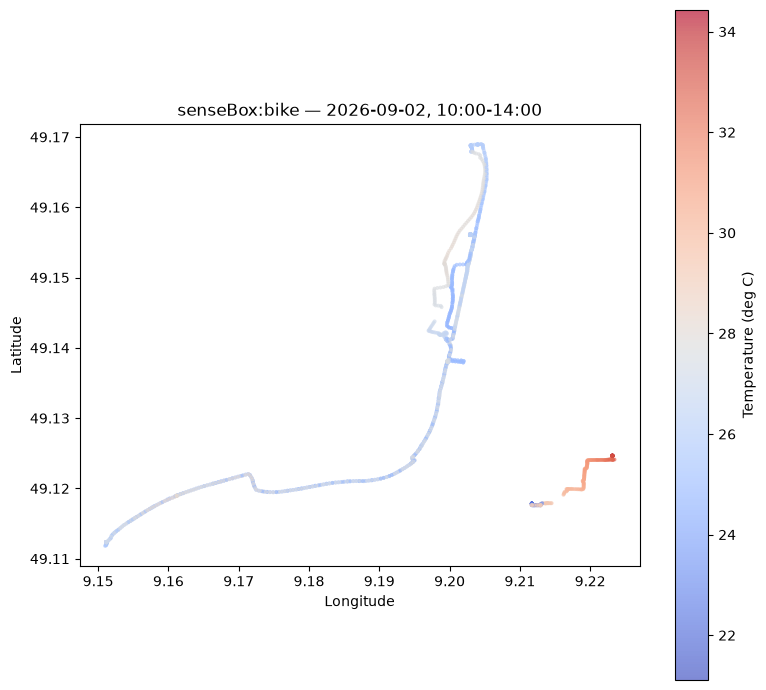

In [6]:
plot_data = window if len(window) <= 20_000 else window.sample(20_000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 7))
points = ax.scatter(
    plot_data["longitude"], plot_data["latitude"], c=plot_data["Temperature"],
    s=8, alpha=0.65, cmap="coolwarm", linewidths=0,
)
fig.colorbar(points, ax=ax, label="Temperature (deg C)")
ax.set(title=f"senseBox:bike — {TARGET_DATE}, {START_TIME}-{END_TIME}", xlabel="Longitude", ylabel="Latitude", aspect="equal")
plt.tight_layout()
plt.show()


## How to use this source responsibly

- `osem_bike_data` is raw, mobile data from multiple campaigns; filtering `groupTags` is essential. The API documentation says its `campaign` parameter currently has no effect.
- A row is a point reading, not an independent citywide sample. Route repetition and dwell time affect counts and apparent hot spots.
- `createdAt` is the measurement timestamp; `created_at` is ingestion time. The sample timestamp has no timezone offset, so do not equate it with CEST until confirmed.
- The selected date cache is in `data/processed/`. Delete that specific cache file or set `REFRESH_CACHE = True` to fetch updated data.
- Compare temperatures only after checking overlapping location, time zone, sensor placement, calibration, and weather exposure. Keep stationary senseBox:home readings as a separate station series.
